### **Model Logging**

In [1]:
"""
parse_model_logs.py — Parser for model-level simulation logs.
==============================================================
Produces two structured CSVs per versioned run:

  1. model_state_{v}.csv      — one row per step with all model state metrics
  2. defection_events_{v}.csv — one row per defection event with threshold,
                                 defection_level (high/medium/low), and rank

Directory layout
────────────────
INPUT  (flat — all runs in one folder, one file per run):
    <PROJECT_ROOT>/SimulationLogs/gemini_flash/ZeroShot/stateful/vision-4/
        ModelLogging/unstructured-logs/
            model_simulation_log_v1.txt
            …

OUTPUT (flat):
    <PROJECT_ROOT>/SimulationLogs/gemini_flash/ZeroShot/stateful/vision-4/
        ModelLogging/structured/
            model_state_v1.csv
            defection_events_v1.csv
            …

Usage
─────
    python parse_model_logs.py
"""

from __future__ import annotations

import csv
import glob
import json
import re
from collections import Counter
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORY CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent

_LOGS_BASE = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"
)

DIRS = {
    "model_dir":        _LOGS_BASE / "unstructured-logs",
    "model_output_dir": _LOGS_BASE / "structured",
}

OUTPUT_STATE_TPL     = "model_state_{v}.csv"
OUTPUT_DEFECTION_TPL = "defection_events_{v}.csv"


# ─────────────────────────────────────────────────────────────────────────────
# REGEX PATTERNS
# ─────────────────────────────────────────────────────────────────────────────

STEP_HEADER    = re.compile(r"^\[Step\s+(\d+)\]\s+\[MODEL\]")
KV_PATTERN     = re.compile(r"(\w+)=([^\s]+)")
INIT_PILLARS   = re.compile(r"\[INIT\]\s+PILLAR_TYPE_COUNTS:\s+(\{.*\})")
DEFECTED_INST  = re.compile(r"defected_institutions=(.+?)(?:\s+\w+=|$)")
INSTITUTION_RE = re.compile(r"institution=(.+?)\s+threshold=")


# ─────────────────────────────────────────────────────────────────────────────
# PARSER
# ─────────────────────────────────────────────────────────────────────────────

def _parse_kv(line: str) -> dict[str, str]:
    return {m.group(1): m.group(2) for m in KV_PATTERN.finditer(line)}


def parse_model_log(filepath: Path) -> tuple[dict, list[dict]]:
    """
    Parse a single model log file.

    Collects:
      - init_info  : PILLAR_TYPE_COUNTS, q33/q66 from step-0 defect_levels,
                     and institution→threshold map from FIRST_DEFECTION lines
      - state_rows : one row per model_state event

    Returns
    -------
    init_info  : dict
    state_rows : list[dict]
    """
    # ── Define NAVCO-style Tiers ──────────────────────────────────────────
    # Logic: Rate = 0.001% relative to a large population
    def get_navco_tier(size):
        # if size < 2:   return -1 # Not a movement yet
        if size <= 2:  return 0  # Tier 0: 1-2 agents
        if size <= 6:  return 1  # Tier 1: 3-6 agents
        if size <= 16: return 2  # Tier 2: 7-16 agents
        if size <= 80: return 3  # Tier 3: 17-80 agents
        if size <= 160:return 4  # Tier 4: 81-160 agents
        return 5                 # Tier 5: > 160 agents


    init_info:  dict       = {
        "pillar_type_counts": {},
        "total_pillars": 0,
        "q33": None,        # defection-level quantile cutoffs from step 0
        "q66": None,
        "thresholds": {},   # institution -> threshold (from FIRST_DEFECTION lines)
    }
    state_rows: list[dict] = []

    with open(filepath, "r", encoding="utf-8", errors="replace") as fh:
        for raw_line in fh:
            line = raw_line.strip()
            if not line:
                continue

            # ── [INIT] PILLAR_TYPE_COUNTS ─────────────────────────────────
            m = INIT_PILLARS.search(line)
            if m:
                try:
                    init_info["pillar_type_counts"] = json.loads(m.group(1))
                    init_info["total_pillars"] = sum(
                        init_info["pillar_type_counts"].values()
                    )
                except json.JSONDecodeError:
                    init_info["pillar_type_counts_raw"] = m.group(1)
                continue

            # ── Lines with a [Step N] header ──────────────────────────────
            step_match = STEP_HEADER.match(line)
            if not step_match:
                continue
            step = int(step_match.group(1))

            # ── defect_levels (step 0) → q33/q66 cutoffs ─────────────────
            if "event=defect_levels" in line:
                kv = _parse_kv(line)
                # Only capture once — step 0 values are the initial distribution
                if init_info["q33"] is None:
                    try:
                        init_info["q33"] = float(kv.get("q33", 0))
                        init_info["q66"] = float(kv.get("q66", 0))
                    except (ValueError, TypeError):
                        pass
                continue

            # ── FIRST_DEFECTION → institution threshold map ───────────────
            if "event=FIRST_DEFECTION" in line:
                kv = _parse_kv(line)
                inst_m = INSTITUTION_RE.search(line)
                institution = inst_m.group(1).strip() if inst_m else kv.get("institution", "")
                try:
                    threshold = float(kv.get("threshold", 0))
                except (ValueError, TypeError):
                    threshold = None
                # Only store the first threshold seen per institution
                # (subsequent instances will have higher thresholds by design)
                if institution and institution not in init_info["thresholds"]:
                    init_info["thresholds"][institution] = threshold
                continue

            # ── model_state ───────────────────────────────────────────────
            if "event=model_state" in line:
                kv = _parse_kv(line)

                di_match = DEFECTED_INST.search(line)
                defected_raw = di_match.group(1).strip() if di_match else "none"
                if defected_raw.lower() == "none" or defected_raw == "":
                    defected_list = []
                else:
                    defected_list = [s.strip() for s in defected_raw.split(",")]

                state_rows.append({
                    "step":                step,
                    "elapsed_s":           kv.get("elapsed", "").rstrip("s"),
                    "legitimacy":          kv.get("legitimacy", ""),
                    "nvCitizen":           kv.get("nvCitizen", ""),
                    "protestingCitizen":   kv.get("protestingCitizen", ""),
                    "protestingActivists": kv.get("protestingActivists", ""),
                    # "resistanceSize":      int(kv.get("protestingCitizen", 0)),
                    # "campSize":            get_navco_tier(int(kv.get("protestingCitizen", 0))),
                    "resistanceSize":      int(kv.get("protestingCitizen", 0)) + int(kv.get("protestingActivists", 0)),
                    "campSize":            get_navco_tier(int(kv.get("protestingCitizen", 0)) + int(kv.get("protestingActivists", 0))),
                    "jailedActivists":     kv.get("jailedActivists", ""),
                    "activists":           kv.get("activists", ""),
                    "police":              kv.get("police", ""),
                    "pillars":             kv.get("pillars", ""),
                    "victory":             kv.get("victory", ""),
                    "defected_count":      len(defected_list),
                    "defected_institutions": "|".join(defected_list),
                    "GrievanceLow":        kv.get("GrievanceLow", ""),
                    "GrievanceMedium":     kv.get("GrievanceMedium", ""),
                    "GrievanceHigh":       kv.get("GrievanceHigh", ""),
                    "q33":                 kv.get("q33", ""),
                    "q66":                 kv.get("q66", ""),
                })

    return init_info, state_rows


# ─────────────────────────────────────────────────────────────────────────────
# DEFECTION LEVEL + RANK HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _defection_level(threshold: float | None, q33: float | None, q66: float | None) -> str:
    """
    Assign defection propensity level based on where the threshold falls
    relative to the population quantiles logged at step 0.

      threshold <= q33  →  "high"    (low threshold = defects early/easily)
      threshold <= q66  →  "medium"
      threshold >  q66  →  "low"     (high threshold = defects late/rarely)

    Returns "" if any value is missing.
    """
    if threshold is None or q33 is None or q66 is None:
        return ""
    if threshold <= q33:
        return "high"
    if threshold <= q66:
        return "medium"
    return "low"


def _institution_rank(institution: str, pillar_type_counts: dict) -> int:
    """
    Derive the ordinal rank of an institution type based on the sorted
    PILLAR_TYPE_COUNTS order (lower rank = lower threshold = defects earlier).

    Institutions are ordered by their position in the counts dict, which
    preserves insertion order (Python 3.7+) and reflects the NAVCO frequency
    ordering used when building PILLAR_ASSIGNMENT_LIST.

    Returns 0-based rank, or -1 if not found.
    """
    for rank, inst in enumerate(pillar_type_counts.keys()):
        if inst == institution:
            return rank + 1
    return -1


# ─────────────────────────────────────────────────────────────────────────────
# DERIVE DEFECTION EVENTS FROM STATE
# ─────────────────────────────────────────────────────────────────────────────

def extract_defections_from_state(
    state_rows: list[dict],
    init_info: dict,
) -> list[dict]:
    """
    Derive defection events by watching defected_institutions grow across steps.

    Uses Counter so duplicate institution names are handled correctly —
    each additional occurrence is a separate defection event.

    Enriches each event with:
      threshold        — from FIRST_DEFECTION log lines (init_info["thresholds"])
      defection_level  — high / medium / low based on q33/q66 cutoffs
      rank             — ordinal position of institution type (0 = earliest defector)
    """
    defect_rows:  list[dict] = []
    prev_counter: Counter    = Counter()

    q33 = init_info.get("q33")
    q66 = init_info.get("q66")
    thresholds      = init_info.get("thresholds", {})
    pillar_counts   = init_info.get("pillar_type_counts", {})

    for row in state_rows:
        raw = row.get("defected_institutions", "")
        if raw and raw.lower() != "none":
            entries = [s.strip() for s in raw.split("|") if s.strip()]
            current_counter: Counter = Counter(entries)
        else:
            current_counter = Counter()

        all_institutions = set(current_counter) | set(prev_counter)
        for institution in sorted(all_institutions):
            increase = current_counter[institution] - prev_counter[institution]
            for _ in range(increase):
                threshold = thresholds.get(institution)
                defect_rows.append({
                    "step":            row["step"],
                    "institution":     institution,
                    "defected_total":  sum(current_counter.values()),
                    "threshold":       threshold if threshold is not None else "",
                    # "defection_level": _defection_level(threshold, q33, q66),
                    "rank":            _institution_rank(institution, pillar_counts),
                })

        prev_counter = current_counter

    return sorted(defect_rows, key=lambda r: r["step"])


# ─────────────────────────────────────────────────────────────────────────────
# CSV WRITERS
# ─────────────────────────────────────────────────────────────────────────────

STATE_COLUMNS = [
    "step", "elapsed_s", "legitimacy",
    "nvCitizen", "protestingCitizen", "protestingActivists",
    "resistanceSize", "campSize",
    "jailedActivists", "activists", "police", "pillars",
    "victory", "defected_count", "defected_institutions",
    "GrievanceLow", "GrievanceMedium", "GrievanceHigh",
    "q33", "q66",
]

DEFECTION_COLUMNS = [
    "step", "institution", "defected_total",
    "threshold", "rank",
]


def write_csv(rows: list[dict], columns: list[str], output_path: Path):
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=columns, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)
    print(f"  -> {output_path}  ({len(rows)} rows)")


# ─────────────────────────────────────────────────────────────────────────────
# DISCOVER RUNS
# ─────────────────────────────────────────────────────────────────────────────

def _version_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.txt$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def discover_versions() -> list[tuple[Path, Path, str]]:
    input_base  = DIRS["model_dir"]
    output_base = DIRS["model_output_dir"]

    log_files = sorted(
        glob.glob(str(input_base / "model_simulation_log_v*.txt")),
        key=_version_num,
    )

    if not log_files:
        raise FileNotFoundError(
            f"No model_simulation_log_v*.txt files found in:\n  {input_base}\n"
            "Check that PROJECT_ROOT points to the right place."
        )

    return [
        (Path(fp), output_base, f"v{_version_num(fp)}")
        for fp in log_files
    ]


# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY
# ─────────────────────────────────────────────────────────────────────────────

def print_summary(
    version_label: str,
    init_info: dict,
    state_rows: list[dict],
    defect_rows: list[dict],
):
    print(f"\n  {'─'*65}")
    print(f"  Summary [{version_label}]")
    print(f"  {'─'*65}")

    if init_info.get("pillar_type_counts"):
        print("  Initial pillar counts:")
        for inst, count in init_info["pillar_type_counts"].items():
            print(f"    {inst:<35} {count}")
        print(f"    {'TOTAL':<35} {init_info.get('total_pillars', '?')}")

    if init_info.get("q33") is not None:
        print(f"\n  Defection level cutoffs:  q33={init_info['q33']}  q66={init_info['q66']}")

    print(f"\n  Steps parsed    : {len(state_rows)}")
    if state_rows:
        final = state_rows[-1]
        print(f"  Final step      : {final['step']}")
        print(f"  Final victory   : {final['victory']}")
        print(f"  Final legitimacy: {final['legitimacy']}")
        print(f"  Final defections: {final['defected_count']}  "
              f"({final['defected_institutions']})")

    print(f"\n  Defection events: {len(defect_rows)}")
    if defect_rows:
        print(f"  {'Institution':<35} {'Step':>5}  {'Threshold':>10}  {'Level':>8}  {'Rank':>5}  {'Total':>6}")
        for r in defect_rows:
            print(
                f"    {r['institution']:<35} {r['step']:>5}  "
                f"{str(r['threshold']):>10}  " 
                # {r['defection_level']:>8}  "
                f"{r['rank']:>5}  {r['defected_total']:>6}"
            )


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

def process_version(log_file: Path, output_dir: Path, version_label: str):
    print(f"\n{'─'*60}")
    print(f"  Run   : {version_label}")
    print(f"  Input : {log_file}")
    print(f"  Output: {output_dir}")
    print(f"{'─'*60}")

    init_info, state_rows = parse_model_log(log_file)
    defect_rows = extract_defections_from_state(state_rows, init_info)

    write_csv(state_rows,  STATE_COLUMNS,     output_dir / "ModelLogs" / OUTPUT_STATE_TPL.format(v=version_label))
    write_csv(defect_rows, DEFECTION_COLUMNS, output_dir / "DefectionLogs" / OUTPUT_DEFECTION_TPL.format(v=version_label))

    print_summary(version_label, init_info, state_rows, defect_rows)


if __name__ == "__main__":
    runs = discover_versions()
    print(f"Discovered {len(runs)} run(s): "
          f"{', '.join(v for _, _, v in runs)}")

    for log_file, output_dir, version_label in runs:
        process_version(log_file, output_dir, version_label)

    print("\n✓ All model log runs processed.")

Discovered 102 run(s): v0, v0, v1, v2, v3, v4, v5, v6, v7, v8, v9, v10, v11, v12, v13, v14, v15, v16, v17, v18, v19, v20, v21, v22, v23, v24, v25, v26, v27, v28, v29, v30, v31, v32, v33, v34, v35, v36, v37, v38, v39, v40, v41, v42, v43, v44, v45, v46, v47, v48, v49, v50, v51, v52, v53, v54, v55, v56, v57, v58, v59, v60, v61, v62, v63, v64, v65, v66, v67, v68, v69, v70, v71, v72, v73, v74, v75, v76, v77, v78, v79, v80, v81, v82, v83, v84, v85, v86, v87, v88, v89, v90, v91, v92, v93, v94, v95, v96, v97, v98, v99, v100

────────────────────────────────────────────────────────────
  Run   : v0
  Input : c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini_flash\ZeroShot\stateful\vision-4\ModelLogging\unstructured-logs\model_simulation_log_v110_.txt
  Output: c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini_flash\ZeroShot\stateful\vision-4\ModelLogging\structured
────────────────────────────────────────────────────────────
  ->

### **Defection Order**

In [2]:
"""
defection_order_plot.py
=======================
Reads defection_events_v*.csv files (one per run) and plots:

  For each defection position (1st, 2nd, 3rd):
    → % of runs where each institution held that position

Output
------
    defection_order_breakdown.png   — grouped bar chart (1 group per position)
    defection_order_breakdown.csv   — raw percentages table
"""

from __future__ import annotations

import csv
import glob
import re
from collections import defaultdict
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent

_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

INPUT_GLOB   = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
OUTPUT_PLOT  = _STRUCTURED / "DefectionAnalysis" / "defection_order_breakdown.png"
OUTPUT_CSV   = _STRUCTURED / "DefectionAnalysis" / "defection_order_breakdown.csv"

# How many ordinal positions to analyse (1st, 2nd, 3rd)
N_POSITIONS  = 3
POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

# Canonical institution order — x-axis always shows all pillars in this order.
# Institutions that never defected in any run will appear with 0% bars.
UNIQUE_PILLAR_TYPES = [
    "Educational System",
    "Trade Unions",
    "Religious Institutions",
    "Professional Associations",
    "Independent Media",
    "Business Community",
    "Civil Service",
    "Local Government",
    "Parliament",
    "Supreme Court",
    "State Media",
]


# ─────────────────────────────────────────────────────────────────────────────
# LOAD & PARSE
# ─────────────────────────────────────────────────────────────────────────────

def _version_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def load_all_runs(glob_pattern: str) -> dict[str, list[dict]]:
    """
    Returns {version_label: [row, row, …]} sorted by step ascending.
    Each row is a dict from the CSV.
    """
    files = sorted(glob.glob(glob_pattern), key=_version_num)
    if not files:
        raise FileNotFoundError(f"No files matched:\n  {glob_pattern}")

    runs = {}
    for fp in files:
        label = f"v{_version_num(fp)}"
        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
        # Sort by step so position 0 = first defection in that run
        rows.sort(key=lambda r: int(r.get("step", 0)))
        runs[label] = rows

    print(f"Loaded {len(runs)} run(s): {list(runs.keys())}")
    return runs


# ─────────────────────────────────────────────────────────────────────────────
# COMPUTE POSITION PERCENTAGES
# ─────────────────────────────────────────────────────────────────────────────

def compute_position_counts(
    runs: dict[str, list[dict]],
    n_positions: int = 3,
) -> tuple[dict[int, dict[str, int]], int]:
    """
    For each ordinal position 1..n_positions, count how many runs each
    institution occupied that position.

    Returns
    -------
    position_counts : {position: {institution: count}}
    total_runs      : total number of runs loaded (denominator for %)
    """
    # {position (1-based): {institution: count}}
    position_counts: dict[int, dict[str, int]] = {
        pos: defaultdict(int) for pos in range(1, n_positions + 1)
    }

    for version, rows in runs.items():
        for pos in range(1, n_positions + 1):
            idx = pos - 1
            if idx < len(rows):
                institution = rows[idx].get("institution", "").strip()
                if institution:
                    position_counts[pos][institution] += 1
            # If run has fewer than pos defections — skip (don't count)

    return position_counts, len(runs)


def to_percentages(
    position_counts: dict[int, dict[str, int]],
    total_runs: int,
) -> dict[int, dict[str, float]]:
    """Convert raw counts to percentages of total_runs."""
    return {
        pos: {inst: round(cnt / total_runs * 100, 1)
              for inst, cnt in sorted(inst_counts.items(),
                                      key=lambda x: -x[1])}
        for pos, inst_counts in position_counts.items()
    }


# ─────────────────────────────────────────────────────────────────────────────
# CSV EXPORT
# ─────────────────────────────────────────────────────────────────────────────

def save_csv(
    pct: dict[int, dict[str, float]],
    total_runs: int,
    output_path: Path,
):
    """
    Wide format:
        institution | 1st_defector_pct | 2nd_defector_pct | 3rd_defector_pct
    """
    # Use canonical order so every institution appears even if never defected
    all_insts = UNIQUE_PILLAR_TYPES

    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w", newline="", encoding="utf-8") as fh:
        cols = ["institution"] + [
            f"pos_{pos}_pct" for pos in sorted(pct)
        ] + ["total_runs"]
        writer = csv.DictWriter(fh, fieldnames=cols)
        writer.writeheader()
        for inst in all_insts:
            row = {"institution": inst, "total_runs": total_runs}
            for pos in sorted(pct):
                row[f"pos_{pos}_pct"] = pct[pos].get(inst, 0.0)
            writer.writerow(row)

    print(f"  CSV  → {output_path}")


# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────

def plot_defection_order(
    pct: dict[int, dict[str, float]],
    total_runs: int,
    output_path: Path,
):
    try:
        import matplotlib.pyplot as plt
        import matplotlib.ticker as ticker
        import numpy as np
    except ImportError:
        print("  matplotlib / numpy not installed — pip install matplotlib numpy")
        return

    # Use canonical order — includes all pillars even if never defected (shows 0%)
    all_insts = UNIQUE_PILLAR_TYPES

    positions  = sorted(pct)
    n_insts    = len(all_insts)
    n_pos      = len(positions)
    x          = np.arange(n_insts)       # one group per institution
    bar_width  = 0.75 / max(n_pos, 1)

    plt.style.use("seaborn-v0_8-whitegrid")

    fig, ax = plt.subplots(figsize=(max(14, n_insts * 1.4), 7))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    # Clean spine styling
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(colors="#333333", labelsize=9, length=3)

    # Professional colour palette — distinct but muted
    pos_colours = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    for i, pos in enumerate(positions):
        offsets = x + (i - n_pos / 2 + 0.5) * bar_width
        values  = [pct.get(pos, {}).get(inst, 0.0) for inst in all_insts]
        colour  = pos_colours.get(pos, "#999999")
        bars    = ax.bar(
            offsets, values,
            width=bar_width * 0.9,
            label=POSITION_LABELS.get(pos, f"Position {pos}"),
            color=colour,
            alpha=0.85,
            edgecolor="white",
            linewidth=0.6,
        )
        # % label on bars tall enough to fit
        for bar, val in zip(bars, values):
            if val >= 0.1:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.8,
                    f"{val:.0f}%",
                    ha="center", va="bottom",
                    color="#222222", fontsize=7.5, fontweight="600",
                )

    ax.set_xticks(x)
    ax.set_xticklabels(all_insts, color="#333333", fontsize=9,
                       rotation=35, ha="right")
    ax.set_ylabel("Probability of Defection", color="#333333", fontsize=11, labelpad=8)
    ax.set_xlabel("Regime Pillars of Support", color="#333333", fontsize=11, labelpad=10)
    ax.set_title(
        f"Pillar Defection Probability by Position  (n={total_runs} runs)",
        color="#111111", fontsize=14, fontweight="bold", pad=16, loc="left",
    )
    ax.text(
        0, 1.01,
        "% of runs each institution was the 1st / 2nd / 3rd pillar to defect",
        transform=ax.transAxes, fontsize=9, color="#666666",
    )
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylim(0, 50)
    ax.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(
        loc="upper right", framealpha=1.0,
        facecolor="white", edgecolor="#cccccc",
        fontsize=10, title="Defection Position",
        title_fontsize=9,
    )

    plt.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=150, bbox_inches="tight",
                facecolor="white")
    plt.close(fig)
    print(f"  Plot → {output_path}")


# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY PRINT
# ─────────────────────────────────────────────────────────────────────────────

def print_summary(pct: dict[int, dict[str, float]], total_runs: int):
    print(f"\n  Total runs: {total_runs}")
    for pos in sorted(pct):
        label = POSITION_LABELS.get(pos, f"Position {pos}")
        print(f"\n  {label}")
        print(f"  {'Institution':<35} {'% of Runs':>10}")
        for inst, p in pct[pos].items():
            bar = "█" * int(p / 5)
            print(f"    {inst:<35} {p:>8.1f}%  {bar}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    runs           = load_all_runs(INPUT_GLOB)
    pos_counts, n  = compute_position_counts(runs, N_POSITIONS)
    pct            = to_percentages(pos_counts, n)

    print_summary(pct, n)
    save_csv(pct, n, OUTPUT_CSV)
    plot_defection_order(pct, n, OUTPUT_PLOT)

    print("\n✓ Done.")

Loaded 107 run(s): ['v0', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'v29', 'v30', 'v31', 'v32', 'v33', 'v34', 'v35', 'v36', 'v37', 'v38', 'v39', 'v40', 'v41', 'v42', 'v43', 'v44', 'v45', 'v46', 'v47', 'v48', 'v49', 'v50', 'v51', 'v52', 'v53', 'v54', 'v55', 'v56', 'v57', 'v58', 'v59', 'v60', 'v61', 'v62', 'v63', 'v64', 'v65', 'v66', 'v67', 'v68', 'v69', 'v70', 'v71', 'v72', 'v73', 'v74', 'v75', 'v76', 'v77', 'v78', 'v79', 'v80', 'v81', 'v82', 'v83', 'v84', 'v85', 'v86', 'v87', 'v88', 'v89', 'v90', 'v91', 'v92', 'v93', 'v94', 'v95', 'v96', 'v97', 'v98', 'v99', 'v100', 'v102', 'v103', 'v104', 'v110', 'v111', 'v114']

  Total runs: 107

  1st Defector
  Institution                          % of Runs
    Trade Unions                            21.5%  ████
    Independent Media                       16.8%  ███
    Educational System                 

In [3]:
# """
# find_defection_files.py
# =======================
# Scans all defection_events_v*.csv files and prints the ones
# where at least 3 institutions defected (i.e. file has >= 3 rows).
# """

# from __future__ import annotations

# import csv
# import glob
# import re
# from pathlib import Path

# # ─────────────────────────────────────────────────────────────────────────────
# # CONFIGURATION
# # ─────────────────────────────────────────────────────────────────────────────

# PROJECT_ROOT = Path.cwd().parent

# _STRUCTURED = (
#     PROJECT_ROOT
#     / "SimulationLogs" / "gemini_flash" / "ZeroShot"
#     / "stateful"       / "vision-4"
#     / "ModelLogging"   / "structured"
# )

# DEFECT_GLOB   = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
# MIN_DEFECTIONS = 3


# # ─────────────────────────────────────────────────────────────────────────────
# # MAIN
# # ─────────────────────────────────────────────────────────────────────────────

# def _vnum(p: str) -> int:
#     m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
#     return int(m.group(1)) if m else 0


# def find_qualifying_files(glob_pat: str, min_defections: int) -> list[tuple[str, int]]:
#     """
#     Returns list of (filename, defection_count) for files with
#     at least min_defections rows.
#     """
#     files = sorted(glob.glob(glob_pat), key=_vnum)

#     if not files:
#         raise FileNotFoundError(f"No files found:\n  {glob_pat}")

#     qualifying = []
#     for fp in files:
#         with open(fp, newline="", encoding="utf-8") as fh:
#             rows = list(csv.DictReader(fh))
#         count = len(rows)
#         if count >= min_defections:
#             qualifying.append((Path(fp).name, count))

#     return qualifying


# if __name__ == "__main__":
#     results = find_qualifying_files(DEFECT_GLOB, MIN_DEFECTIONS)

#     print(f"\nFiles with >= {MIN_DEFECTIONS} defections:\n")
#     print(f"  {'File':<40} {'Defections':>10}")
#     print(f"  {'─'*40} {'─'*10}")
#     for fname, count in results:
#         print(f"  {fname:<40} {count:>10}")

#     print(f"\n  Total qualifying runs: {len(results)}")

### **Probability of Sucess vs Participation Size**

  Loaded 99 runs  |  victories: 75  |  log10_pct range: [-0.78, 0.48]


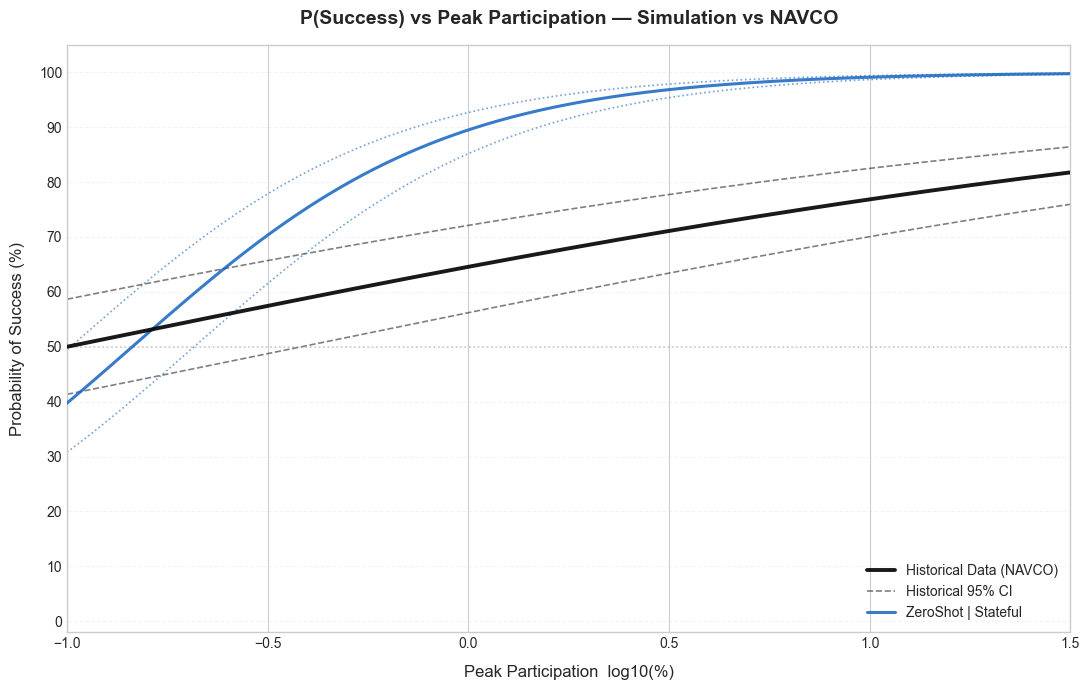


Visualization exported to: Analysis\plots\success_curves_with_ci.png


In [4]:
from probablity_win_analysis import plot_success_curves_vs_historical
from pathlib import Path

plot_success_curves_vs_historical(
    output_dir     = Path("Analysis/plots"),
    sim_population = 1217,
    version_start  = 1,
    version_end    = 100,
)

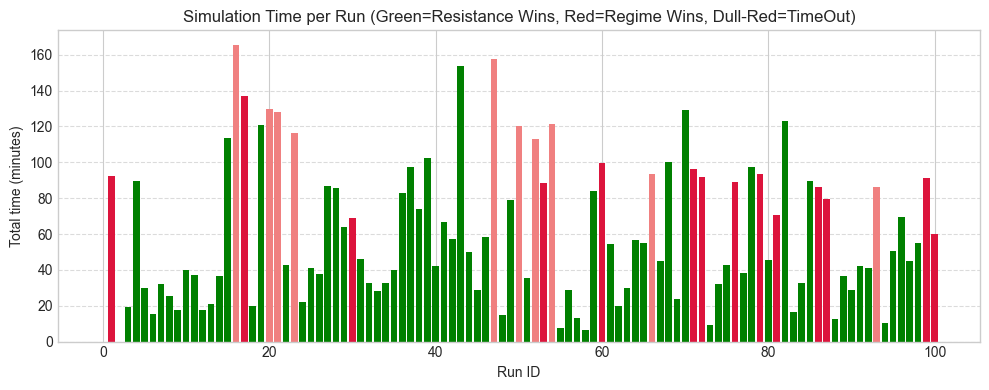

In [5]:
import pandas as pd 
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

# Use the existing Path object logic
PROJECT_ROOT = Path.cwd().parent

_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

# 1. Define the pattern
INPUT_PATTERN = str(_STRUCTURED / "ModelLogs" / "model_state_v*.csv")

records = []

# 2. Use glob.glob to actually find the files on disk
files = glob.glob(INPUT_PATTERN)

if not files:
    print(f"No files found matching: {INPUT_PATTERN}")
else:
    for path_str in sorted(files):
        path = Path(path_str)
        df = pd.read_csv(path)
        
        # 3. Robust extraction of the version/run number
        # Looks for 'v' followed by digits (e.g., model_state_v1.csv -> 1)
        match = re.search(r'v(\d+)', path.name)
        run_id = int(match.group(1)) if match else 0
        
        # 4. Handle possible empty DataFrames safely
        if not df.empty and "elapsed_s" in df.columns:
            records.append({
                "run_id":      run_id,
                "total_min":    df["elapsed_s"].sum() / 60,
                "mean_step_s":  df["elapsed_s"].mean(),
                "n_steps":      len(df),
                "victory":      df["victory"].iloc[-1] if "victory" in df.columns else 0,
            })

if records:
    summary = pd.DataFrame(records).sort_values("run_id")

    # 5. Plotting with better color handling
    plt.figure(figsize=(10, 4))
    
    # Map colors: 1=Regime (Crimson), 2=Resistance (Seagreen), 3=Draw (Gray)
    colors = summary["victory"].map({1: "#DC143C", 2: "#008000", 3: "#F08080"}).fillna("blue")
        # colors = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    
    plt.bar(summary["run_id"], summary["total_min"], color=colors)
    plt.xlabel("Run ID")
    plt.ylabel("Total time (minutes)")
    plt.title("Simulation Time per Run (Green=Resistance Wins, Red=Regime Wins, Dull-Red=TimeOut)")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("No records processed. Check if the CSV files contain 'elapsed_s' and 'victory' columns.")

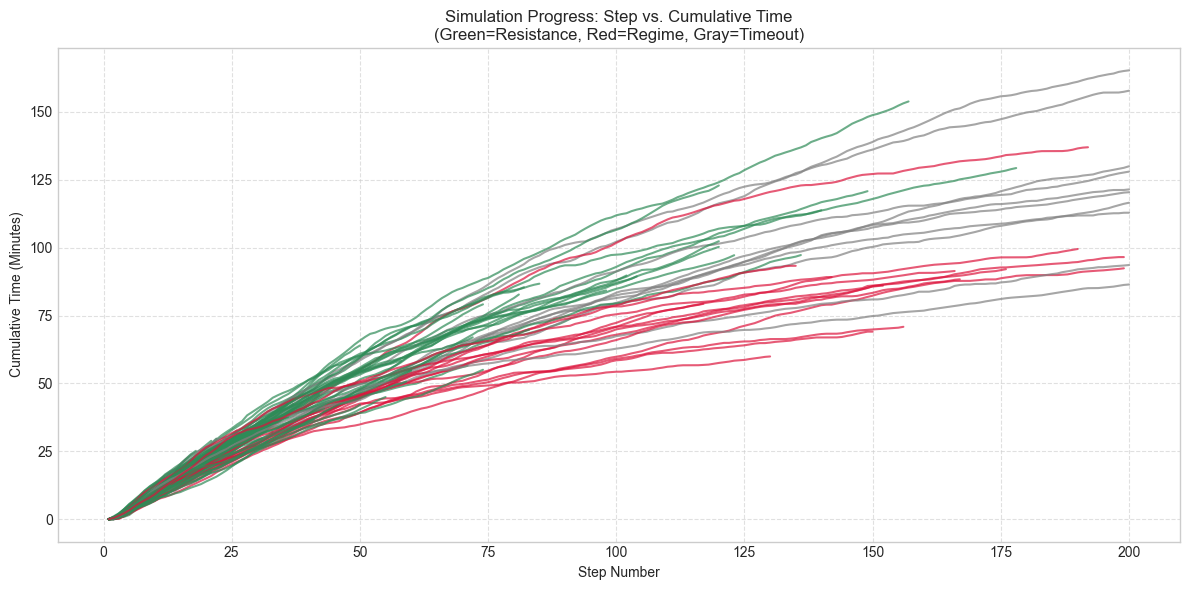

In [6]:
import pandas as pd 
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

INPUT_PATTERN = str(_STRUCTURED / "ModelLogs" / "model_state_v*.csv")
files = glob.glob(INPUT_PATTERN)

plt.figure(figsize=(12, 6))

if not files:
    print(f"No files found matching: {INPUT_PATTERN}")
else:
    # Sort files to ensure the legend stays organized
    for path_str in sorted(files):
        path = Path(path_str)
        df = pd.read_csv(path)
        
        # 1. Extract Run ID for the legend
        match = re.search(r'v(\d+)', path.name)
        run_id = f"Run {match.group(1)}" if match else path.name
        
        if not df.empty and "elapsed_s" in df.columns:
            # 2. Calculate Cumulative Time in minutes
            # This shows the 'total clock time' as the simulation progresses
            df['cumulative_min'] = df['elapsed_s'].cumsum() / 60
            
            # 3. Determine color based on final victory (optional but helpful)
            final_victory = df["victory"].iloc[-1] if "victory" in df.columns else 0
            color_map = {1: "crimson", 2: "seagreen", 3: "gray"}
            line_color = color_map.get(final_victory, "blue")
            
            # 4. Plot Step vs Cumulative Time
            # If 'step' column doesn't exist, we use df.index
            x_axis = df['step'] if 'step' in df.columns else df.index
            
            plt.plot(x_axis, df['cumulative_min'], 
                     label=run_id, 
                     color=line_color, 
                     alpha=0.7, 
                     linewidth=1.5)

    # 5. Formatting the Plot
    plt.xlabel("Step Number")
    plt.ylabel("Cumulative Time (Minutes)")
    plt.title("Simulation Progress: Step vs. Cumulative Time\n(Green=Resistance, Red=Regime, Gray=Timeout)")
    
    # Plotting raw seconds per step instead of cumulative
    # plt.scatter(x_axis, df['elapsed_s'], alpha=0.3, s=10) 
    # plt.ylabel("Seconds per Step")

    # Legend can get crowded if you have many runs, adjust as needed
    # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', ncol=2)
    
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

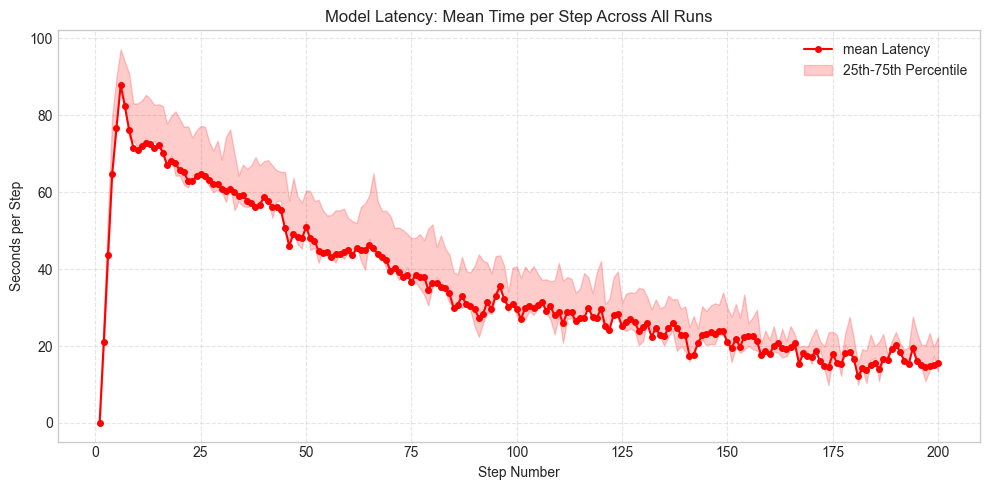

Analysis complete. Overall Mean step time: 45.28 seconds.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
from pathlib import Path

# 1. Setup Paths
PROJECT_ROOT = Path.cwd().parent
_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

INPUT_PATTERN = str(_STRUCTURED / "ModelLogs" / "model_state_v*.csv")
files = glob.glob(INPUT_PATTERN)

all_data = []

if not files:
    print(f"No files found matching: {INPUT_PATTERN}")
else:
    # 2. Collect all steps from all runs
    for path_str in files:
        df = pd.read_csv(path_str)
        if not df.empty and "elapsed_s" in df.columns:
            # Ensure we have a 'step' column (fallback to index)
            if 'step' not in df.columns:
                df['step'] = df.index
            
            # We only need these two columns for this specific plot
            all_data.append(df[['step', 'elapsed_s']])

    # 3. Combine and Aggregate
    # Concatenate all runs into one big DataFrame
    combined_df = pd.concat(all_data)

    # Calculate mean, 25th, and 75th percentiles per step
    stats_per_step = combined_df.groupby('step')['elapsed_s'].agg(['mean', 'quantile', lambda x: x.quantile(0.75)]).reset_index()
    # Cleaning up column names from the quantile calls
    stats_per_step.columns = ['step', 'mean', 'q25', 'q75']

    # 4. Plotting
    plt.figure(figsize=(10, 5))

    # Plot the mean line
    plt.plot(stats_per_step['step'], stats_per_step['mean'], 
             color='red', marker='o', markersize=4, label='mean Latency')

    # Add shaded area for Interquartile Range (IQR) - shows the consistency
    plt.fill_between(stats_per_step['step'], stats_per_step['q25'], stats_per_step['q75'], 
                     color='red', alpha=0.2, label='25th-75th Percentile')

    # Overall mean (horizontal line for reference)
    overall_mean = combined_df['elapsed_s'].mean()
    # plt.axhline(y=overall_mean, color='red', linestyle='--', alpha=0.6, 
    #             label=f'Overall mean: {overall_mean:.2f}s')

    # Formatting
    plt.xlabel("Step Number")
    plt.ylabel("Seconds per Step")
    plt.title("Model Latency: Mean Time per Step Across All Runs")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    print(f"Analysis complete. Overall Mean step time: {overall_mean:.2f} seconds.")

Total files found: 107
Successful runs (Victory 2) included: 76


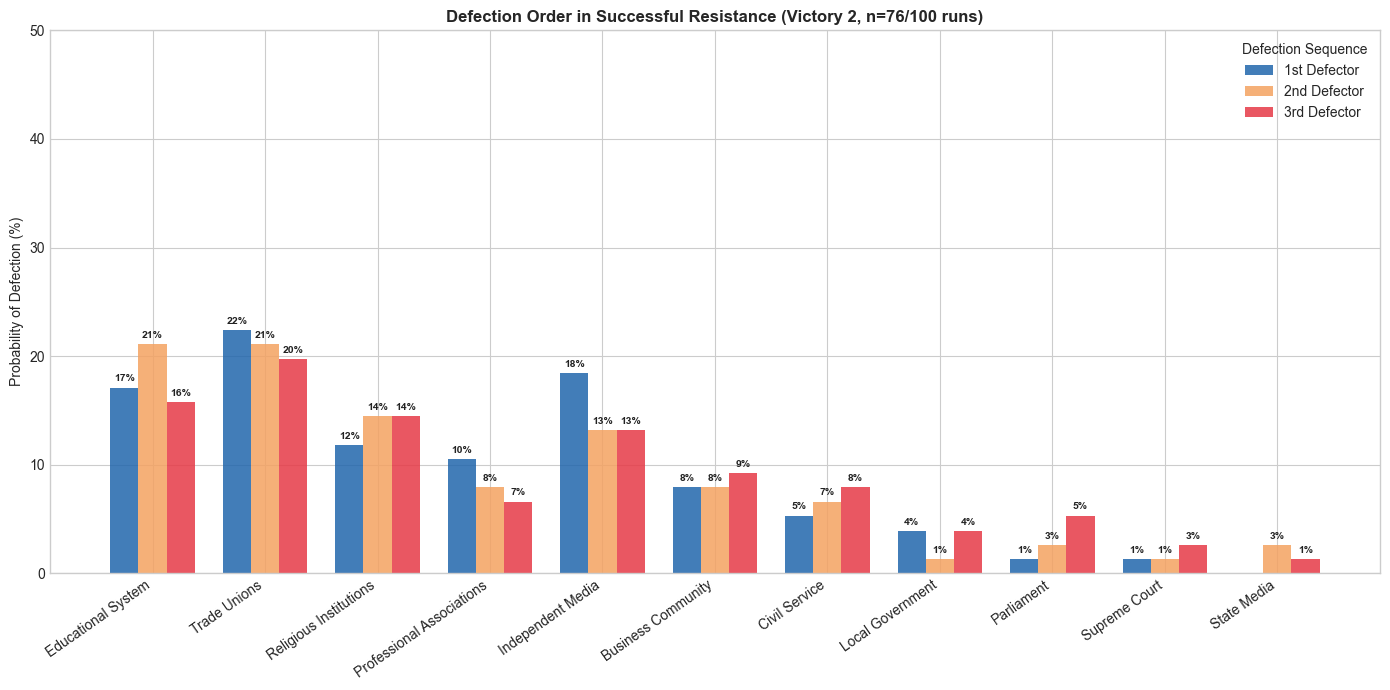

Success! Plot saved to: c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\gemini_flash\ZeroShot\stateful\vision-4\ModelLogging\structured\DefectionAnalysis\successful_defection_order_breakdown_victory_2.png


In [8]:
"""
defection_order_analysis.py
===========================
Analyzes the sequence of pillar defections specifically for successful 
movements (Victory 2). Cross-references defection events with model states.
"""

from __future__ import annotations
import os
import csv
import glob
import re
from collections import defaultdict
from pathlib import Path

# --- FIX FOR OPENMP CONFLICT ---
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent

_STRUCTURED = (
    PROJECT_ROOT
    / "SimulationLogs" / "gemini_flash" / "ZeroShot"
    / "stateful"       / "vision-4"
    / "ModelLogging"   / "structured"
)

# Paths for input data
DEFECTION_GLOB = str(_STRUCTURED / "DefectionLogs" / "defection_events_v*.csv")
MODEL_STATE_DIR = _STRUCTURED / "ModelLogs"

# Paths for output
OUTPUT_DIR = _STRUCTURED / "DefectionAnalysis"
OUTPUT_PLOT = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.png"
OUTPUT_CSV  = OUTPUT_DIR / "successful_defection_order_breakdown_victory_2.csv"

N_POSITIONS = 3
POSITION_LABELS = {1: "1st Defector", 2: "2nd Defector", 3: "3rd Defector"}

UNIQUE_PILLAR_TYPES = [
    "Educational System", "Trade Unions", "Religious Institutions",
    "Professional Associations", "Independent Media", "Business Community",
    "Civil Service", "Local Government", "Parliament", "Supreme Court", "State Media",
]

# ─────────────────────────────────────────────────────────────────────────────
# DATA LOADING & FILTERING
# ─────────────────────────────────────────────────────────────────────────────

def _get_v_num(p: str) -> int:
    m = re.search(r"_v(\d+)\.csv$", p, re.IGNORECASE)
    return int(m.group(1)) if m else 0

def load_successful_runs(glob_pattern: str) -> dict[str, list[dict]]:
    """Filters for runs where the final state is Victory 2."""
    files = sorted(glob.glob(glob_pattern), key=_get_v_num)
    if not files:
        raise FileNotFoundError(f"No files matched pattern: {glob_pattern}")

    successful_runs = {}
    total_found = 0

    for fp in files:
        v_num = _get_v_num(fp)
        label = f"v{v_num}"
        total_found += 1
        
        # Check corresponding model state for Victory 2
        state_file = MODEL_STATE_DIR / f"model_state_v{v_num}.csv"
        if not state_file.exists():
            continue
            
        try:
            state_df = pd.read_csv(state_file)
            if state_df.empty or state_df["victory"].iloc[-1] != 2:
                continue # Only care about Victory 2
        except Exception:
            continue

        # Load defection sequence
        with open(fp, newline="", encoding="utf-8") as fh:
            rows = list(csv.DictReader(fh))
            rows.sort(key=lambda r: int(r.get("step", 0)))
            successful_runs[label] = rows

    print(f"Total files found: {total_found}")
    print(f"Successful runs (Victory 2) included: {len(successful_runs)}")
    return successful_runs

# ─────────────────────────────────────────────────────────────────────────────
# PROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def process_stats(runs: dict[str, list[dict]]):
    total_n = len(runs)
    if total_n == 0:
        return None, 0

    # Count occurrences per position
    pos_counts = {pos: defaultdict(int) for pos in range(1, N_POSITIONS + 1)}
    for rows in runs.values():
        for pos in range(1, N_POSITIONS + 1):
            idx = pos - 1
            if idx < len(rows):
                inst = rows[idx].get("institution", "").strip()
                if inst:
                    pos_counts[pos][inst] += 1

    # Convert to percentages
    pct_results = {
        pos: {inst: round(cnt / total_n * 100, 1) for inst, cnt in inst_counts.items()}
        for pos, inst_counts in pos_counts.items()
    }
    return pct_results, total_n

# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZATION & EXPORT
# ─────────────────────────────────────────────────────────────────────────────

def run_analysis():
    # 1. Load and Process
    runs = load_successful_runs(DEFECTION_GLOB)
    pct, n = process_stats(runs)
    
    if not pct:
        print("No successful runs found to analyze.")
        return

    # 2. Save CSV
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        header = ["institution"] + [f"pos_{p}_pct" for p in range(1, N_POSITIONS + 1)]
        writer.writerow(header)
        for inst in UNIQUE_PILLAR_TYPES:
            row = [inst] + [pct[p].get(inst, 0.0) for p in range(1, N_POSITIONS + 1)]
            writer.writerow(row)

    # 3. Plotting
    plt.style.use("seaborn-v0_8-whitegrid")
    fig, ax = plt.subplots(figsize=(14, 7), facecolor="white")
    
    x = np.arange(len(UNIQUE_PILLAR_TYPES))
    width = 0.25
    colors = {1: "#2166ac", 2: "#f4a261", 3: "#e63946"}

    for i, pos in enumerate(range(1, N_POSITIONS + 1)):
        vals = [pct[pos].get(inst, 0.0) for inst in UNIQUE_PILLAR_TYPES]
        offset = (i - 1) * width
        rects = ax.bar(x + offset, vals, width, label=POSITION_LABELS[pos], color=colors[pos], alpha=0.85)
        
        # Add text labels on top of bars
        for rect in rects:
            height = rect.get_height()
            if height > 0:
                ax.annotate(f'{height:.0f}%',
                            xy=(rect.get_x() + rect.get_width() / 2, height),
                            xytext=(0, 3), textcoords="offset points",
                            ha='center', va='bottom', fontsize=7.5, fontweight="600", color="#222222",)

    ax.set_xticks(x)
    ax.set_ylim(0, 50)
    ax.set_xticklabels(UNIQUE_PILLAR_TYPES, rotation=35, ha="right")
    ax.set_ylabel("Probability of Defection (%)")
    ax.set_title(f"Defection Order in Successful Resistance (Victory 2, n={n}/100 runs)", fontweight="bold")
    ax.legend(title="Defection Sequence")
    
    plt.tight_layout()
    plt.savefig(OUTPUT_PLOT, dpi=150)
    plt.show()
    print(f"Success! Plot saved to: {OUTPUT_PLOT}")

if __name__ == "__main__":
    run_analysis()